## 1. Imports and settings

In [95]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# fixed seed so the results are the same every time the notebook is run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# the four classes in order from worst to best, used for tables and plots
CLASSES = ['unacc', 'acc', 'good', 'vgood']
plt.rcParams['figure.dpi'] = 110

## 2. Load data

In [96]:
# car.data has no header row, so the column names come from car.names
cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data_file = 'car.data'

# on Colab the file has to be uploaded first
if not os.path.exists(data_file):
    try:
        from google.colab import files
        print('Please upload car.data')
        files.upload()
    except ImportError:
        raise FileNotFoundError('car.data not found, put it in the same folder as this notebook')

# dtype=str because every attribute is categorical (even doors and persons)
df = pd.read_csv(data_file, names=cols, dtype=str)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 3. Dataset information

In [97]:
print('Rows and columns:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print()
df.info()

Rows and columns: (1728, 7)
Missing values: 0
Duplicate rows: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [98]:
# the values each attribute can take
for c in cols:
    print(f'{c:9s}', sorted(df[c].unique()))

buying    ['high', 'low', 'med', 'vhigh']
maint     ['high', 'low', 'med', 'vhigh']
doors     ['2', '3', '4', '5more']
persons   ['2', '4', 'more']
lug_boot  ['big', 'med', 'small']
safety    ['high', 'low', 'med']
class     ['acc', 'good', 'unacc', 'vgood']


       count  percent
class                
unacc   1210     70.0
acc      384     22.2
good      69      4.0
vgood     65      3.8


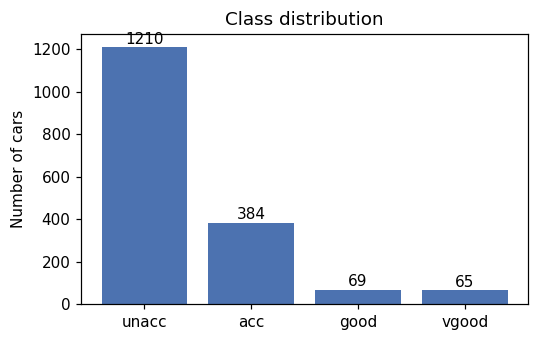

In [99]:
# class distribution, the dataset is heavily imbalanced
counts = df['class'].value_counts().reindex(CLASSES)
summary = pd.DataFrame({'count': counts, 'percent': (counts / len(df) * 100).round(1)})
print(summary)

plt.figure(figsize=(5, 3.2))
plt.bar(CLASSES, counts.values, color='#4C72B0')
for i, v in enumerate(counts.values):
    plt.text(i, v + 15, str(v), ha='center')
plt.ylabel('Number of cars')
plt.title('Class distribution')
plt.tight_layout()
plt.show()

## 4. Baselines

In [100]:
def metrics(y_true, y_pred):
    # macro F1 treats every class equally, so the rare classes (good, vgood) count as much as unacc
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro', labels=CLASSES, zero_division=0)


class MajorityBaseline:
    def fit(self, X, y):
        self.label = y.value_counts().idxmax()
        return self

    def predict(self, X):
        return np.array([self.label] * len(X))


class OneR:
    def fit(self, X, y):
        best_acc = -1
        for attr in X.columns:
            # for each value of the attribute, predict the most common class
            table = y.groupby(X[attr]).agg(lambda s: s.value_counts().idxmax())
            acc = (X[attr].map(table) == y).mean()
            if acc > best_acc:
                best_acc, self.attr, self.table = acc, attr, table
        self.default = y.value_counts().idxmax()
        return self

    def predict(self, X):
        return X[self.attr].map(self.table).fillna(self.default).values

## 5. Train/test split


In [101]:
X = df.drop(columns='class')
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print(pd.DataFrame({'train': y_train.value_counts().reindex(CLASSES),
                    'test': y_test.value_counts().reindex(CLASSES)}))

Train: (1209, 6)  Test: (519, 6)
       train  test
class             
unacc    847   363
acc      269   115
good      48    21
vgood     45    20


In [102]:
maj = MajorityBaseline().fit(X_train, y_train)
oner = OneR().fit(X_train, y_train)

print('Majority baseline  acc=%.3f  macroF1=%.3f' % metrics(y_test, maj.predict(X_test)))
print('1R (attribute: %s)  acc=%.3f  macroF1=%.3f' % ((oner.attr,) + metrics(y_test, oner.predict(X_test))))

Majority baseline  acc=0.699  macroF1=0.206
1R (attribute: buying)  acc=0.699  macroF1=0.206


## 6. Algorithm A: expert rule base

In [103]:
# "cheap" is my own definition of a low overall price (buying price + maintenance)
def cheap(d):
    return ((d.buying == 'low') & d.maint.isin(['low', 'med'])) | ((d.buying == 'med') & (d.maint == 'low'))

expert_rules = [
    ('persons = 2',                                       lambda d: d.persons == '2',                                     'unacc'),
    ('safety = low',                                      lambda d: d.safety == 'low',                                    'unacc'),
    ('buying = vhigh AND maint in {vhigh, high}',         lambda d: (d.buying == 'vhigh') & d.maint.isin(['vhigh', 'high']), 'unacc'),
    ('buying = high AND maint = vhigh',                   lambda d: (d.buying == 'high') & (d.maint == 'vhigh'),          'unacc'),
    ('cheap AND safety = high AND lug_boot = big',        lambda d: cheap(d) & (d.safety == 'high') & (d.lug_boot == 'big'), 'vgood'),
    ('cheap AND safety = high AND lug_boot = med AND persons = more',
                                                          lambda d: cheap(d) & (d.safety == 'high') & (d.lug_boot == 'med') & (d.persons == 'more'), 'vgood'),
    ('cheap AND safety = high',                           lambda d: cheap(d) & (d.safety == 'high'),                      'good'),
    ('cheap AND safety = med AND lug_boot in {med, big}', lambda d: cheap(d) & (d.safety == 'med') & d.lug_boot.isin(['med', 'big']), 'good'),
]
expert_default = 'acc'


class ExpertSystem:
    # no training needed, the knowledge is already in the rules
    def fit(self, X, y=None):
        return self

    def predict(self, X, return_rule_ids=False):
        labels = np.full(len(X), expert_default, dtype=object)
        fired = np.full(len(X), len(expert_rules))
        done = np.zeros(len(X), dtype=bool)
        for i, (name, cond, cls) in enumerate(expert_rules):
            hit = cond(X).values & ~done
            labels[hit] = cls
            fired[hit] = i
            done |= hit
        return (labels, fired) if return_rule_ids else labels

    def n_rules(self):
        return len(expert_rules) + 1


for i, (name, _, cls) in enumerate(expert_rules, 1):
    print(f'R{i}: IF {name} THEN {cls}')
print(f'R{len(expert_rules) + 1}: DEFAULT THEN {expert_default}')

R1: IF persons = 2 THEN unacc
R2: IF safety = low THEN unacc
R3: IF buying = vhigh AND maint in {vhigh, high} THEN unacc
R4: IF buying = high AND maint = vhigh THEN unacc
R5: IF cheap AND safety = high AND lug_boot = big THEN vgood
R6: IF cheap AND safety = high AND lug_boot = med AND persons = more THEN vgood
R7: IF cheap AND safety = high THEN good
R8: IF cheap AND safety = med AND lug_boot in {med, big} THEN good
R9: DEFAULT THEN acc


## 7. Algorithm B: CN2-style rule induction

In [104]:
class CN2:
    def __init__(self, beam_width=3, min_cover=3, min_quality=0.6):
        self.beam_width = beam_width
        self.min_cover = min_cover
        self.min_quality = min_quality

    def _quality(self, mask, y_idx):

        n = mask.sum()
        if n == 0:
            return 0, None
        counts = np.bincount(y_idx[mask], minlength=len(self.classes_))
        best = counts.argmax()
        return (counts[best] + 1) / (n + len(self.classes_)), best

    def _find_best_rule(self, masks, y_idx, alive):

        beam = [((), alive)]
        best_rule, best_q, best_cls = None, 0, None
        while beam:
            candidates = []
            for conds, mask in beam:
                used = {a for a, v in conds}
                for (attr, val), m in masks.items():
                    if attr in used:
                        continue
                    new_mask = mask & m
                    if new_mask.sum() < self.min_cover:
                        continue
                    q, cls = self._quality(new_mask, y_idx)
                    candidates.append((q, conds + ((attr, val),), new_mask, cls))
            if not candidates:
                break
            candidates.sort(key=lambda c: c[0], reverse=True)
            beam = [(c[1], c[2]) for c in candidates[:self.beam_width]]
            if candidates[0][0] > best_q:
                best_q, best_rule, best_cls = candidates[0][0], candidates[0][1], candidates[0][3]
            # a rule that is already pure can't be improved, so stop specialising
            if candidates[0][0] >= 0.99:
                break
        return best_rule, best_q, best_cls

    def fit(self, X, y):
        self.classes_ = sorted(y.unique())
        y_idx = y.map({c: i for i, c in enumerate(self.classes_)}).values
        # one boolean mask per (attribute, value) pair so the search is fast
        masks = {(a, v): (X[a] == v).values for a in X.columns for v in X[a].unique()}
        alive = np.ones(len(X), dtype=bool)
        self.rules = []
        while alive.sum() > 0:
            rule, q, cls = self._find_best_rule(masks, y_idx, alive)
            if rule is None or q < self.min_quality:
                break
            covered = alive.copy()
            for a, v in rule:
                covered &= masks[(a, v)]
            self.rules.append((rule, self.classes_[cls], q, int(covered.sum())))
            alive &= ~covered

        pool = y_idx[alive] if alive.sum() > 0 else y_idx
        self.default = self.classes_[np.bincount(pool, minlength=len(self.classes_)).argmax()]
        return self

    def predict(self, X, return_rule_ids=False):
        labels = np.full(len(X), self.default, dtype=object)
        fired = np.full(len(X), len(self.rules))
        done = np.zeros(len(X), dtype=bool)
        for i, (conds, cls, q, n) in enumerate(self.rules):
            hit = np.ones(len(X), dtype=bool)
            for a, v in conds:
                hit &= (X[a] == v).values
            hit &= ~done
            labels[hit] = cls
            fired[hit] = i
            done |= hit
        return (labels, fired) if return_rule_ids else labels

    def n_rules(self):
        return len(self.rules) + 1

    def show(self):
        for i, (conds, cls, q, n) in enumerate(self.rules, 1):
            text = ' AND '.join(f'{a} = {v}' for a, v in conds)
            print(f'R{i}: IF {text} THEN {cls}   (covers {n}, laplace {q:.2f})')
        print(f'R{len(self.rules) + 1}: DEFAULT THEN {self.default}')

## 8. Hold-out evaluation

In [105]:
expert = ExpertSystem().fit(X_train)
cn2 = CN2().fit(X_train, y_train)

print('Rules learned by CN2 on the training set:\n')
cn2.show()

Rules learned by CN2 on the training set:

R1: IF safety = low THEN unacc   (covers 409, laplace 0.99)
R2: IF persons = 2 THEN unacc   (covers 263, laplace 0.99)
R3: IF buying = vhigh AND maint = high THEN unacc   (covers 39, laplace 0.93)
R4: IF maint = vhigh AND buying = high THEN unacc   (covers 32, laplace 0.92)
R5: IF buying = high AND lug_boot = big THEN acc   (covers 39, laplace 0.93)
R6: IF maint = high AND buying = med AND safety = high THEN acc   (covers 18, laplace 0.82)
R7: IF lug_boot = med AND buying = high AND safety = high THEN acc   (covers 19, laplace 0.87)
R8: IF maint = high AND buying = low AND safety = med THEN acc   (covers 15, laplace 0.79)
R9: IF buying = high AND safety = med AND lug_boot = small THEN unacc   (covers 19, laplace 0.87)
R10: IF buying = high AND lug_boot = small THEN acc   (covers 19, laplace 0.74)
R11: IF maint = med AND buying = vhigh AND safety = high THEN acc   (covers 18, laplace 0.86)
R12: IF buying = vhigh AND maint = vhigh THEN unacc   (

In [106]:
def average_rule_length(rules):
    return np.mean([len(r[0]) for r in rules])

pred_e, fired_e = expert.predict(X_test, return_rule_ids=True)
pred_c, fired_c = cn2.predict(X_test, return_rule_ids=True)

rows = []
for name, pred, fired, n_rules, avg_len in [
        ('Majority baseline', maj.predict(X_test), None, 1, 0),
        ('1R', oner.predict(X_test), None, len(oner.table) + 1, 1),
        ('Expert rules', pred_e, fired_e, expert.n_rules(), np.mean([len(name.split(' AND ')) for name, _, _ in expert_rules])),
        ('CN2', pred_c, fired_c, cn2.n_rules(), average_rule_length(cn2.rules))]:
    acc, f1 = metrics(y_test, pred)
    default_used = '' if fired is None else round((fired == (n_rules - 1)).mean() * 100, 1)
    rows.append([name, round(acc, 3), round(f1, 3), n_rules, default_used])

holdout = pd.DataFrame(rows, columns=['Method', 'Accuracy', 'Macro-F1', 'No. of rules', '% decided by default rule'])
print(holdout.to_string(index=False))

           Method  Accuracy  Macro-F1  No. of rules % decided by default rule
Majority baseline     0.699     0.206             1                          
               1R     0.699     0.206             5                          
     Expert rules     0.921     0.842             9                      29.1
              CN2     0.961     0.901            39                       5.6


In [107]:
# per-class precision / recall / F1
for name, pred in [('Expert rules', pred_e), ('CN2', pred_c)]:
    print('=' * 60)
    print(name)
    print(classification_report(y_test, pred, labels=CLASSES, zero_division=0, digits=3))

Expert rules
              precision    recall  f1-score   support

       unacc      1.000     0.920     0.958       363
         acc      0.755     0.991     0.857       115
        good      0.870     0.952     0.909        21
       vgood      0.909     0.500     0.645        20

    accuracy                          0.921       519
   macro avg      0.883     0.841     0.842       519
weighted avg      0.937     0.921     0.922       519

CN2
              precision    recall  f1-score   support

       unacc      1.000     0.975     0.987       363
         acc      0.857     0.991     0.919       115
        good      0.944     0.810     0.872        21
       vgood      1.000     0.700     0.824        20

    accuracy                          0.961       519
   macro avg      0.950     0.869     0.901       519
weighted avg      0.966     0.961     0.961       519



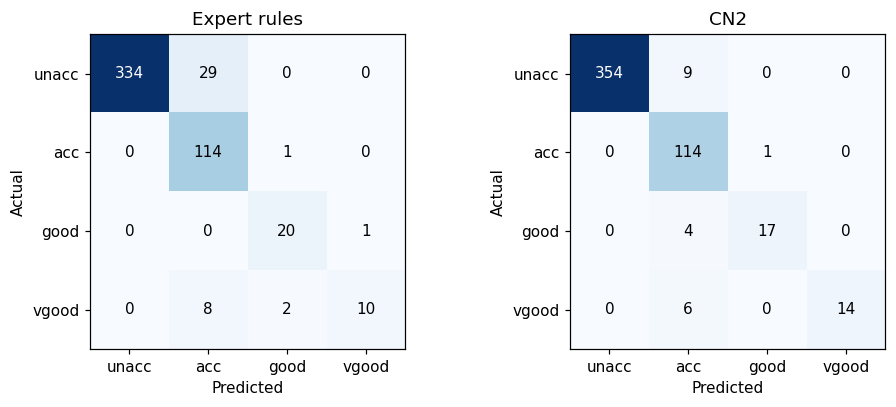

In [108]:
# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, pred) in zip(axes, [('Expert rules', pred_e), ('CN2', pred_c)]):
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(name)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

## 9. Repeated cross-validation

In [109]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
cv_rows = []
for train_idx, test_idx in rskf.split(X, y):
    Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
    ytr, yte = y.iloc[train_idx], y.iloc[test_idx]
    model = CN2().fit(Xtr, ytr)
    one = OneR().fit(Xtr, ytr)
    for name, pred, n in [('Majority baseline', MajorityBaseline().fit(Xtr, ytr).predict(Xte), 1),
                          ('1R', one.predict(Xte), len(one.table) + 1),
                          ('Expert rules', expert.predict(Xte), expert.n_rules()),
                          ('CN2', model.predict(Xte), model.n_rules())]:
        acc, f1 = metrics(yte, pred)
        cv_rows.append([name, acc, f1, n])

cv = pd.DataFrame(cv_rows, columns=['Method', 'Accuracy', 'MacroF1', 'Rules'])
cv_summary = cv.groupby('Method').agg(
    acc_mean=('Accuracy', 'mean'), acc_std=('Accuracy', 'std'),
    f1_mean=('MacroF1', 'mean'), f1_std=('MacroF1', 'std'),
    rules_mean=('Rules', 'mean')).round(3).loc[['Majority baseline', '1R', 'Expert rules', 'CN2']]
print(cv_summary)

                   acc_mean  acc_std  f1_mean  f1_std  rules_mean
Method                                                           
Majority baseline     0.700    0.001    0.206   0.000        1.00
1R                    0.700    0.001    0.206   0.000        5.00
Expert rules          0.913    0.011    0.828   0.034        9.00
CN2                   0.944    0.016    0.835   0.074       36.16


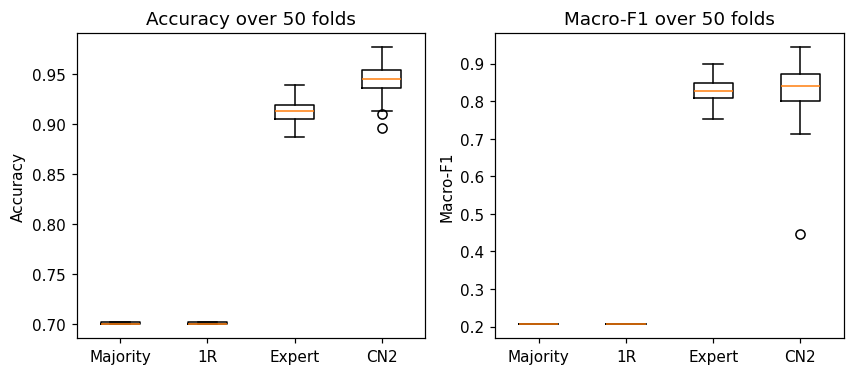

In [110]:
# box plot of the 50 fold scores
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
order = ['Majority baseline', '1R', 'Expert rules', 'CN2']
for ax, col, title in zip(axes, ['Accuracy', 'MacroF1'], ['Accuracy', 'Macro-F1']):
    ax.boxplot([cv[cv.Method == m][col] for m in order])
    ax.set_xticklabels(['Majority', '1R', 'Expert', 'CN2'])
    ax.set_title(title + ' over 50 folds')
    ax.set_ylabel(title)

## 10. Significance test

In [111]:
a = cv[cv.Method == 'Expert rules'].reset_index(drop=True)
b = cv[cv.Method == 'CN2'].reset_index(drop=True)

for col in ['Accuracy', 'MacroF1']:
    diff = b[col] - a[col]
    t, p = stats.ttest_rel(b[col], a[col])
    print(f'{col}: CN2 - Expert mean difference = {diff.mean():+.4f}, paired t-test p = {p:.4g}')
    try:
        w, pw = stats.wilcoxon(b[col], a[col])
        print(f'{col}: Wilcoxon signed-rank p = {pw:.4g}')
    except ValueError:
        print(f'{col}: Wilcoxon not possible (all differences are zero)')

Accuracy: CN2 - Expert mean difference = +0.0312, paired t-test p = 2.345e-19
Accuracy: Wilcoxon signed-rank p = 1.594e-09
MacroF1: CN2 - Expert mean difference = +0.0075, paired t-test p = 0.5069
MacroF1: Wilcoxon signed-rank p = 0.1407


## 11. Learning curve

          n_train    acc     f1  rules
fraction                              
0.05         60.0  0.780  0.382    5.1
0.10        120.0  0.802  0.394    8.0
0.20        241.0  0.844  0.504   12.8
0.30        362.0  0.865  0.533   15.0
0.50        604.0  0.907  0.723   24.0
0.70        846.0  0.925  0.769   28.9
1.00       1209.0  0.961  0.901   39.0


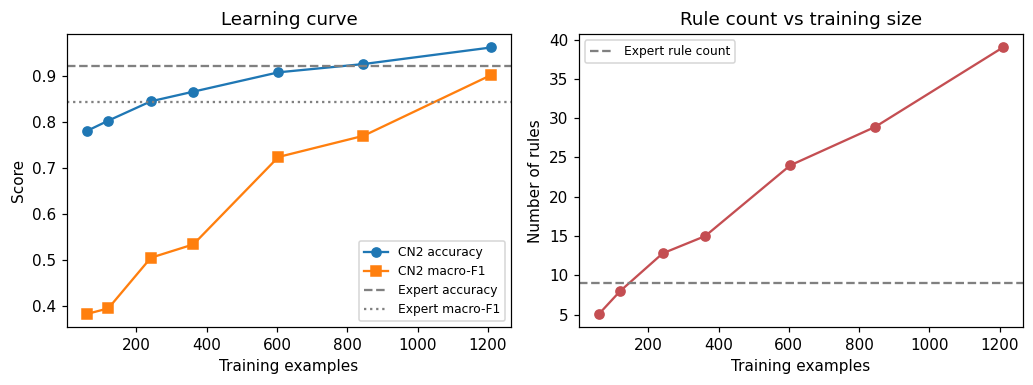

In [112]:
fractions = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
repeats = 10
lc = []
for frac in fractions:
    for r in range(repeats):
        if frac < 1.0:
            Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=frac,
                                            stratify=y_train, random_state=SEED + r)
        else:
            Xs, ys = X_train, y_train
        m = CN2().fit(Xs, ys)
        acc, f1 = metrics(y_test, m.predict(X_test))
        lc.append([frac, len(Xs), acc, f1, m.n_rules()])

lc = pd.DataFrame(lc, columns=['fraction', 'n_train', 'acc', 'f1', 'rules'])
lc_mean = lc.groupby('fraction').mean().round(3)
print(lc_mean)

exp_acc, exp_f1 = metrics(y_test, pred_e)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].plot(lc_mean.n_train, lc_mean.acc, marker='o', label='CN2 accuracy')
axes[0].plot(lc_mean.n_train, lc_mean.f1, marker='s', label='CN2 macro-F1')
axes[0].axhline(exp_acc, color='grey', ls='--', label='Expert accuracy')
axes[0].axhline(exp_f1, color='grey', ls=':', label='Expert macro-F1')
axes[0].set_xlabel('Training examples'); axes[0].set_ylabel('Score'); axes[0].legend(fontsize=8)
axes[0].set_title('Learning curve')
axes[1].plot(lc_mean.n_train, lc_mean.rules, marker='o', color='#C44E52')
axes[1].axhline(expert.n_rules(), color='grey', ls='--', label='Expert rule count')
axes[1].set_xlabel('Training examples'); axes[1].set_ylabel('Number of rules'); axes[1].legend(fontsize=8)
axes[1].set_title('Rule count vs training size')
plt.tight_layout()
plt.show()

## 12. Noise robustness

         acc     f1  rules
noise                     
0.00   0.961  0.901   39.0
0.05   0.899  0.648   37.4
0.10   0.852  0.501   43.9
0.20   0.709  0.356   39.2
0.30   0.645  0.277   34.2


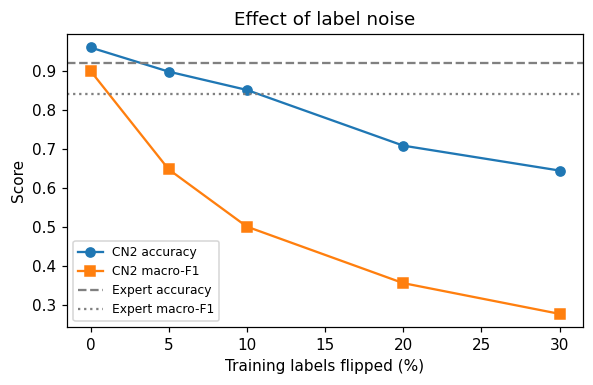

In [113]:
def add_label_noise(labels, rate, rng):
    labels = labels.copy().values
    n_flip = int(rate * len(labels))
    idx = rng.choice(len(labels), size=n_flip, replace=False)
    for i in idx:
        labels[i] = rng.choice([c for c in CLASSES if c != labels[i]])
    return pd.Series(labels, index=y_train.index)

noise_levels = [0, 0.05, 0.10, 0.20, 0.30]
nz = []
for rate in noise_levels:
    for r in range(10):
        rng = np.random.default_rng(SEED + r)
        noisy = add_label_noise(y_train, rate, rng)
        m = CN2().fit(X_train, noisy)
        acc, f1 = metrics(y_test, m.predict(X_test))
        nz.append([rate, acc, f1, m.n_rules()])

nz = pd.DataFrame(nz, columns=['noise', 'acc', 'f1', 'rules'])
nz_mean = nz.groupby('noise').mean().round(3)
print(nz_mean)

plt.figure(figsize=(5.5, 3.6))
plt.plot(nz_mean.index * 100, nz_mean.acc, marker='o', label='CN2 accuracy')
plt.plot(nz_mean.index * 100, nz_mean.f1, marker='s', label='CN2 macro-F1')
plt.axhline(exp_acc, color='grey', ls='--', label='Expert accuracy')
plt.axhline(exp_f1, color='grey', ls=':', label='Expert macro-F1')
plt.xlabel('Training labels flipped (%)'); plt.ylabel('Score')
plt.title('Effect of label noise'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 13. Final summary table

In [114]:
final = pd.DataFrame({
    'Hold-out accuracy': holdout.set_index('Method')['Accuracy'],
    'Hold-out macro-F1': holdout.set_index('Method')['Macro-F1'],
    'CV accuracy (mean)': cv_summary['acc_mean'],
    'CV macro-F1 (mean)': cv_summary['f1_mean'],
    'No. of rules': holdout.set_index('Method')['No. of rules'],
})
print(final)

                   Hold-out accuracy  Hold-out macro-F1  CV accuracy (mean)  \
Method                                                                        
Majority baseline              0.699              0.206               0.700   
1R                             0.699              0.206               0.700   
Expert rules                   0.921              0.842               0.913   
CN2                            0.961              0.901               0.944   

                   CV macro-F1 (mean)  No. of rules  
Method                                               
Majority baseline               0.206             1  
1R                              0.206             5  
Expert rules                    0.828             9  
CN2                             0.835            39  
